# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI - LAB ĐƯỢC CHẠY TRÊN KAGGLE NOTEBOOK

### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 1.1. Cài thư viện

In [51]:
!pip install underthesea seqeval

#### 1.2. Kiểm tra đường dẫn

In [52]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from seqeval.metrics import f1_score as ent_f1, precision_score as ent_precision, recall_score as ent_recall
from seqeval.metrics import classification_report as ent_report
from seqeval.metrics.sequence_labeling import get_entities
from seqeval.scheme import IOB2

print(os.listdir("/kaggle/input/datasets/xuancuong1019/uit-vsfc"))

['UIT-VSFC-dev.json', 'UIT-VSFC-test.json', 'UIT-VSFC-train.json']


#### 1.3. Kiểm tra kích thước dữ liệu

In [53]:
DATA_DIR = "/kaggle/input/datasets/xuancuong1019/uit-vsfc"

uit_train_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-train.json")
uit_dev_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-dev.json")
uit_test_df = pd.read_json(f"{DATA_DIR}/UIT-VSFC-test.json")

print("Train:", uit_train_df.shape)
print("Dev:", uit_dev_df.shape)
print("Test:", uit_test_df.shape)

Train: (11426, 3)
Dev: (1583, 3)
Test: (3166, 3)


#### 1.4. Kiểm tra phân phối nhãn

In [54]:
print(uit_train_df['sentiment'].value_counts())
print("\nSố lượng nhãn:", uit_train_df['sentiment'].nunique())

sentiment
positive    5643
negative    5325
neutral      458
Name: count, dtype: int64

Số lượng nhãn: 3


#### 1.5. Mã hóa sentiment

In [55]:
label2id = {'negative': 0, 'neutral': 1, 'positive': 2}
id2label = {0: 'negative', 1: 'neutral', 2: 'positive'}
CLASS_NAMES = ['negative', 'neutral', 'positive']

for df in [uit_train_df, uit_dev_df, uit_test_df]:
    df['label'] = df['sentiment'].map(label2id)
    

#### 1.6. Tokenization bằng underthesea

In [56]:
from underthesea import word_tokenize

def tokenize(text):
    return word_tokenize(str(text).lower())

for df in [uit_train_df, uit_dev_df, uit_test_df]:
    df['tokens'] = df['sentence'].apply(tokenize)


#### 1.7. Thống kê độ dài câu (số từ) sau khi tokenize để chọn max_length

In [57]:
train_lengths = uit_train_df['tokens'].apply(len)
print(train_lengths.describe())
print(train_lengths.quantile([0.90, 0.95, 0.99]))

count    11426.000000
mean        11.151147
std          8.080817
min          2.000000
25%          6.000000
50%          9.000000
75%         14.000000
max        122.000000
Name: tokens, dtype: float64
0.90    21.00
0.95    26.75
0.99    42.00
Name: tokens, dtype: float64


#### 1.8. Khảo sát dataset chọn min_freq

In [58]:
token_freq = Counter()
for tokens in uit_train_df['tokens']:
    token_freq.update(tokens)

total_tokens = sum(token_freq.values())
singletons= sum(1 for f in token_freq.values() if f == 1)


print("Tổng số token:", total_tokens)
print("Số token khác nhau:", len(token_freq))
print("Token xuất hiện 1 lần:", singletons)

for min_freq in [1,2,3,5,10]:
    vocab_size = 0
    kept = 0
    for f in token_freq.values():
        if f >= min_freq:
            vocab_size += 1
            kept += f
    print("min_freq =", min_freq, "| vocab =", vocab_size, "| coverage = %.2f%%" % (kept / total_tokens * 100))


Tổng số token: 127413
Số token khác nhau: 4009
Token xuất hiện 1 lần: 1932
min_freq = 1 | vocab = 4009 | coverage = 100.00%
min_freq = 2 | vocab = 2077 | coverage = 98.48%
min_freq = 3 | vocab = 1611 | coverage = 97.75%
min_freq = 5 | vocab = 1217 | coverage = 96.70%
min_freq = 10 | vocab = 839 | coverage = 94.74%


#### 1.9. Xây dựng từ điển

In [59]:
PAD, UNK = 0, 1
MIN_FREQ = 2
MAX_LENGTH = 35

def build_vocab(token_lists):
    counter = Counter()
    for tokens in token_lists:
        counter.update(tokens)
    vocab = {"<pad>": PAD, "<unk>": UNK}
    for token, count in sorted(counter.items()):
        if count >= MIN_FREQ:
            vocab[token] = len(vocab)
    return vocab

vocab = build_vocab(uit_train_df['tokens'])
print("Kích thước từ điển:", len(vocab))
print("Token minh họa:", tokenize("giảng viên dạy rất hay"))

Kích thước từ điển: 2079
Token minh họa: ['giảng viên', 'dạy', 'rất', 'hay']


#### 1.10. Encoding 

In [60]:
def encode(tokens):
    ids = [vocab.get(t, UNK) for t in tokens]
    if len(ids) == 0:
        ids = [UNK]
    return ids

for df in [uit_train_df, uit_dev_df, uit_test_df]:
    df['input_ids'] = df['tokens'].apply(encode)

print("Tokens:", uit_train_df['tokens'].iloc[0])
print("Input IDs:", uit_train_df['input_ids'].iloc[0])
print("Label:", uit_train_df['sentiment'].iloc[0])

Tokens: ['slide', 'giáo trình', 'đầy đủ', '.']
Input IDs: [1331, 503, 1995, 10]
Label: positive


#### 1.11. Padding/Truncation

In [61]:
def pad_truncate(ids):
    ids = ids[:MAX_LENGTH]
    return ids + [PAD] * (MAX_LENGTH - len(ids)) 

for df in [uit_train_df, uit_dev_df, uit_test_df]:
    df['input_ids'] = df['input_ids'].apply(pad_truncate)

#### 1.12. Khởi tạo dataset

In [62]:
class SentimentDataset(Dataset):
    def __init__(self, df):
        self.x = torch.tensor(df['input_ids'].tolist())
        self.y = torch.tensor(df['label'].tolist())

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]

uit_train_dataset = SentimentDataset(uit_train_df)
uit_dev_dataset = SentimentDataset(uit_dev_df)
uit_test_dataset = SentimentDataset(uit_test_df)

#### 1.13. DataLoader

In [63]:
BATCH_SIZE = 32

train_loader = DataLoader(uit_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
dev_loader = DataLoader(uit_dev_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(uit_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

input_ids, label = next(iter(train_loader))

print("Input shape:", input_ids.shape)
print("Labels shape:", label.shape)

Input shape: torch.Size([32, 35])
Labels shape: torch.Size([32])


#### 1.14. Đặt seed, GPU

In [64]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang dùng:", device)
if device.type == "cuda":
    print("Tên GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
    
set_seed(42)

Thiết bị đang dùng: cuda
Tên GPU: Tesla T4


#### 1.15. Embedding -> LSTM (5 layer, hidden_size = 256) -> Linear (3 lớp)

In [65]:
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, kind="LSTM", emb_dim=300, hidden_size=256, layers=5, dropout=0.3, num_classes=3):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD) 
        if kind == "LSTM":
            self.rnn = nn.LSTM(emb_dim, hidden_size, num_layers = layers, batch_first=True, dropout = dropout)
        else:
            self.rnn = nn.GRU(emb_dim, hidden_size, num_layers= layers, batch_first=True, dropout = dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, num_classes)
     

    def forward(self, x):
        lengths = (x != PAD).sum(dim=1)               
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        if self.kind == "LSTM":
            _, (h_n, _) = self.rnn(packed)  
        else:
            _, h_n = self.rnn(packed)
        return self.fc(self.dropout(h_n[-1]))   

#### 1.16. Khởi tạo model LSTM

In [66]:
set_seed(42)
lstm_model = TextClassifier(len(vocab), kind="LSTM").to(device)
print(lstm_model)
print("Số tham số LSTM:", count_params(lstm_model))
del lstm_model

TextClassifier(
  (embedding): Embedding(2079, 300, padding_idx=0)
  (rnn): LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
Số tham số LSTM: 3301207


#### 1.17. Hàm loss và hàm tối ưu

In [67]:
criterion = nn.CrossEntropyLoss()  
LR = 1e-3

#### 1.18. Hàm huấn luyện 1 epoch và hàm evaluate (loss + F1)

In [68]:
def train_one_epoch(model, loader, optimizer):
    model.train()  
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()                                     
        loss = criterion(model(x), y)
        loss.backward()                      
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  
        optimizer.step()                      
        total_loss += loss.item() * x.size(0) 
    return total_loss / len(loader.dataset)


def evaluate(model, loader):
    model.eval()  
    total_loss = 0
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += criterion(logits, y).item() * x.size(0)
            preds += logits.argmax(dim=1).cpu().tolist()
            labels += y.cpu().tolist()
    f1 = f1_score(labels, preds, average="macro")
    return total_loss / len(loader.dataset), f1, preds, labels

#### 1.19. Training loop

In [69]:
results = {}

def train_model(name, kind, epochs=10):
    set_seed(42)
    model = TextClassifier(len(vocab), kind=kind).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr = LR)

    history = {"train_loss": [], "dev_loss": [], "dev_f1": []}
    best_f1 = 0
    best_epoch = 0
    best_state = None
    epoch_times = []

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer)
        dev_loss, dev_f1, _, _ = evaluate(model, dev_loader)
        epoch_times.append(time.time() - start)

        history["train_loss"].append(train_loss)
        history["dev_loss"].append(dev_loss)
        history["dev_f1"].append(dev_f1)

        if dev_f1 > best_f1:
            best_f1 = dev_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print("Epoch %2d | train loss %.4f | dev loss %.4f | dev F1 %.4f" % (epoch, train_loss, dev_loss, dev_f1))

    results[name] = {}
    results[name]["kind"] = kind
    results[name]["history"] = history
    results[name]["best_dev_f1"] = best_f1
    results[name]["best_epoch"] = best_epoch
    results[name]["best_state"] = best_state
    results[name]["sec_per_epoch"] = sum(epoch_times) / len(epoch_times)
    results[name]["n_params"] = count_params(model)

    print("Best dev F1: %.4f (epoch %d)" % (best_f1, best_epoch))

train_model("lstm", "LSTM")

Epoch  1 | train loss 0.4480 | dev loss 0.3564 | dev F1 0.6060
Epoch  2 | train loss 0.3068 | dev loss 0.2895 | dev F1 0.7200
Epoch  3 | train loss 0.2559 | dev loss 0.2828 | dev F1 0.7169
Epoch  4 | train loss 0.2201 | dev loss 0.2790 | dev F1 0.7601
Epoch  5 | train loss 0.1922 | dev loss 0.3074 | dev F1 0.7913
Epoch  6 | train loss 0.1649 | dev loss 0.2961 | dev F1 0.8069
Epoch  7 | train loss 0.1446 | dev loss 0.3394 | dev F1 0.7610
Epoch  8 | train loss 0.1237 | dev loss 0.3302 | dev F1 0.7837
Epoch  9 | train loss 0.1084 | dev loss 0.3321 | dev F1 0.7883
Epoch 10 | train loss 0.1007 | dev loss 0.3241 | dev F1 0.7750
Best dev F1: 0.8069 (epoch 6)


#### 1.20. Đường cong loss

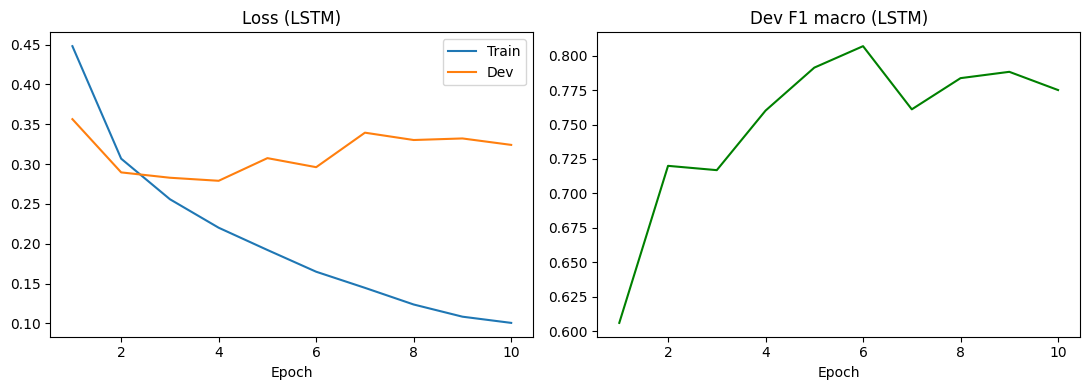

In [70]:
def plot_history(name):
    h = results[name]["history"]
    epochs = range(1, len(h["train_loss"]) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="Train")
    ax[0].plot(epochs, h["dev_loss"], label="Dev")
    ax[0].set_title("Loss (" + name.upper() + ")")
    ax[0].set_xlabel("Epoch")
    ax[0].legend()

    ax[1].plot(epochs, h["dev_f1"], color="green")
    ax[1].set_title("Dev F1 macro (" + name.upper() + ")")
    ax[1].set_xlabel("Epoch")
    plt.tight_layout()
    plt.show()

plot_history("lstm")

#### Nhận xét: 
* Train loss: giảm qua từng epoch (từ 0.45 xuống 0.1) cho thấy LSTM học được các đặc trưng hữu ích
* Dev loss: giảm đến thấp nhất ở epoch 4, sau đó tăng lên trong khi train loss vẫn giảm. Sau epoch 4 có dấu hiệu overfit
* Dev F1 macro: tăng đến đỉnh ở epoch 6, sau đó dao động trong khoảng 0.76 đến 0.79

#### 1.21. Load model tốt nhất dự đoán test

In [71]:
def test_and_report(name):
    model = TextClassifier(len(vocab), kind=results[name]["kind"]).to(device)
    model.load_state_dict(results[name]["best_state"])
    _, f1_macro, preds, labels = evaluate(model, test_loader)

    print(name.upper(), "- Test F1 macro: %.4f" % f1_macro)
    print(classification_report(labels, preds, target_names=CLASS_NAMES, digits=4, zero_division=0))

    results[name]["test_preds"] = preds
    results[name]["test_labels"] = labels
    results[name]["test_f1_macro"] = f1_macro

test_and_report("lstm")

LSTM - Test F1 macro: 0.7475
              precision    recall  f1-score   support

    negative     0.8970    0.9454    0.9205      1409
     neutral     0.4828    0.3353    0.3958       167
    positive     0.9335    0.9189    0.9261      1590

    accuracy                         0.8999      3166
   macro avg     0.7711    0.7332    0.7475      3166
weighted avg     0.8935    0.8999    0.8957      3166



#### Nhận xét: 
* Tổng thể: LSTM đạt accuracy 0.8999 trên test, phân loại đúng gần như 90% số lượng câu.
* F1 macro: F1 macro chỉ có 0.7475, thấp hơn accuracy khá nhiều, cho thấy kết quả không đồng đều giữa các lớp
* 3 lớp phân loại: F1 lần lượt là 0.9205 và 0.9261 ở negative và positive, hai lớp này được phân loại tốt và gần như ngang nhau. Trong khi đó thì F1 neutral chỉ được 0.3958, đây là lớp yếu nhất và cũng chính là nguyên nhân kéo F1 macro xuống
* Precision và recall của neutral: precision đạt 0.4828 có nghĩa là trong các lần dự đoán neutral có nó thì chưa tới một nửa đúng, còn recall chỉ đạt 0.3353 nghĩa là mô hình bỏ sót gần 66% câu neutral thực tế. Nguyên nhân chính là vì neutral có quá ít mẫu so với hai lớp còn lại, nên mô hình ít được học lớp này

#### 1.22 Confusion matrix

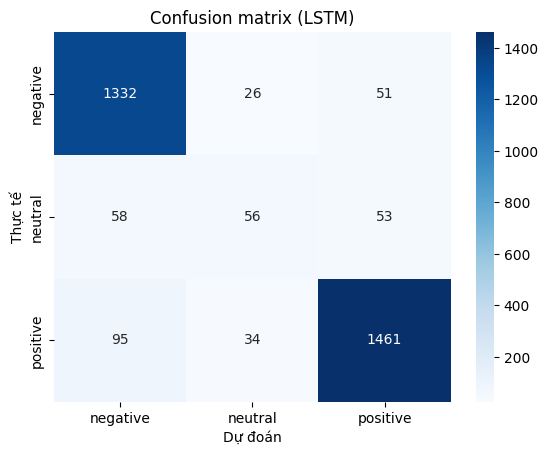

In [72]:
def plot_cm(name):
    cm = confusion_matrix(results[name]["test_labels"], results[name]["test_preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title("Confusion matrix (" + name.upper() + ")")
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
    plt.show()

plot_cm("lstm")

#### Nhận xét:
* Hai lớp lớn: negative đúng 1332/1409 và positive đúng 1461/1590, đạt kết quả tốt

* Lớp neutral: chỉ đúng 56/167, còn lại bị đoán sang positive (53) và negative (58)

* Đáng chú ý, negative và positive nhầm lẫn ở mức khá, 51 câu negative bị đoán positive và 95 câu positive bị đoán thành negative

#### 1.23 Phân tích lỗi trên dev

In [73]:
def error_analysis(name, n=3):
    model = TextClassifier(len(vocab), kind=results[name]["kind"]).to(device)
    model.load_state_dict(results[name]["best_state"])
    model.eval()

    preds, confs = [], []
    with torch.no_grad():
        for x, y in dev_loader:
            probs = torch.softmax(model(x.to(device)), dim=1)
            conf, pred = probs.max(dim=1)
            preds += pred.cpu().tolist()
            confs += conf.cpu().tolist()

    print(name.upper(), "- 3 câu dự đoán sai trên dev:\n")
    count = 0
    for i in range(len(preds)):
        true_label = uit_dev_df["label"].iloc[i]
        if preds[i] != true_label:
            print("Câu:", uit_dev_df["sentence"].iloc[i])
            print("Thật:", id2label[true_label], "| Dự đoán:", id2label[preds[i]], "| Độ tự tin: %.2f" % confs[i])
            print()
            count += 1
            if count == n:
                break

error_analysis("lstm")

LSTM - 3 câu dự đoán sai trên dev:

Câu: thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .
Thật: neutral | Dự đoán: positive | Độ tự tin: 0.99

Câu: cô rất nghiêm .
Thật: negative | Dự đoán: positive | Độ tự tin: 0.97

Câu: ngoài ra cung cấp một vài thông tin bổ sung về việc học công nghệ thông tin hiệu quả hơn .
Thật: positive | Dự đoán: negative | Độ tự tin: 0.87



#### Nhận xét:

* Câu 1: Theo quan điểm cá nhân thì câu này nên được gán là negative thay vì neutral. Vì câu có ý chê việc sinh viên bị cho tự tìm hiểu thay vì dạy. Mô hình đoán positive với độ tụ tin gần như tuyệt đối, có thể mô hình bám vào cum "tự tìm hiểu" thay vì hiểu cả câu
  
* Câu 2: Câu ngắn và thiếu ngữ cảnh chi tiết. Có thể ngữ cảnh được trình bày trên câu hỏi. "Nghiêm" có thể là ưu điểm hoặc nhược điểm tùy người đánh giá nên nhãn negative có phần mơ hồ. Mô hình đoán positive với độ tự tin 0.97, có thể vì không có từ nào khác để dựa vào.

* Câu 3: Câu này mô tả nhiều hơn là biểu đạt cảm xúc. Các cụm từ như "bổ sung", "hiệu quả hơn" đều mang nghĩa tích cực nên nhãn positive là hợp lý. Mô hình đoán negative với độ tự tin 0.87 nên đây là lỗi của mô hình

* **Kết luận:** Qua các lỗi trên thì tạm thời mô hình LSTM gồm 2 loại lõi là nhãn mơ hồ và mô hình hiểu sai. Và đoán sai nhưng độ tự tin lại rất cao

#### 1.24 Baseline TF-IDF

Số đặc trưng TF-IDF: 12855
C = 0.1 | dev F1-macro: 0.6029 | fit: 1.7s
C = 1 | dev F1-macro: 0.6852 | fit: 4.1s
C = 10 | dev F1-macro: 0.7385 | fit: 5.0s
C = 100 | dev F1-macro: 0.7342 | fit: 3.0s

Chọn C = 10 | Test F1-macro: 0.7018


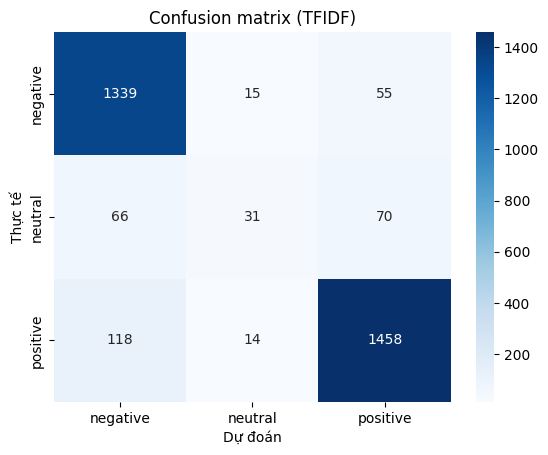

In [75]:
def to_text(tokens):
    return " ".join(t.replace(" ", "_") for t in tokens)

train_text = uit_train_df["tokens"].apply(to_text)
dev_text = uit_dev_df["tokens"].apply(to_text)
test_text = uit_test_df["tokens"].apply(to_text)

y_train = uit_train_df["label"].values
y_dev = uit_dev_df["label"].values
y_test = uit_test_df["label"].values

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_text)
X_dev = tfidf.transform(dev_text)
X_test = tfidf.transform(test_text)
print("Số đặc trưng TF-IDF:", X_train.shape[1])

best_f1 = 0
for C in [0.1, 1, 10, 100]:
    start = time.time()
    clf = LogisticRegression(C=C, max_iter=1000)
    clf.fit(X_train, y_train)
    fit_time = time.time() - start

    dev_f1 = f1_score(y_dev, clf.predict(X_dev), average="macro")
    print("C =", C, "| dev F1-macro: %.4f | fit: %.1fs" % (dev_f1, fit_time))

    if dev_f1 > best_f1:
        best_f1 = dev_f1
        best_C = C
        best_time = fit_time
        best_clf = clf

tfidf_preds = best_clf.predict(X_test)
tfidf_test_f1 = f1_score(y_test, tfidf_preds, average="macro")

results["tfidf"] = {}
results["tfidf"]["best_dev_f1"] = best_f1
results["tfidf"]["fit_time"] = best_time
results["tfidf"]["config"] = "ngram(1,2), min_df=2, C=" + str(best_C)
results["tfidf"]["n_params"] = best_clf.coef_.size + best_clf.intercept_.size
results["tfidf"]["test_preds"] = tfidf_preds.tolist()
results["tfidf"]["test_labels"] = y_test.tolist()
results["tfidf"]["test_f1_macro"] = tfidf_test_f1

print("\nChọn C =", best_C, "| Test F1-macro: %.4f" % tfidf_test_f1)
plot_cm("tfidf")

### Nhận xét:
* Hai lớp lớn: negative đúng 1339/1409 và positive đúng 1458/1590, tương đương positive
* Lớp neutral: chỉ đúng 31/167, kém hơn LSTM rõ. Mô hình hầu như không dám đoán neutral (cả cột chỉ có 60 câu)
* Đáng lưu ý là chỉ có 118 câu positive bị đoán thành negative, nhiều hơn LSTM

### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 2.1. Khởi tạo model GRU

In [76]:
set_seed(42)
gru_model = TextClassifier(len(vocab), kind="GRU").to(device)
print(gru_model)
print("Số tham số GRU:", count_params(gru_model))
del gru_model

TextClassifier(
  (embedding): Embedding(2079, 300, padding_idx=0)
  (rnn): GRU(300, 256, num_layers=5, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)
Số tham số GRU: 2632023


#### 2.2. Training loop

In [77]:
train_model("gru", "GRU")

Epoch  1 | train loss 0.4138 | dev loss 0.3210 | dev F1 0.6106
Epoch  2 | train loss 0.2944 | dev loss 0.2773 | dev F1 0.7143
Epoch  3 | train loss 0.2474 | dev loss 0.2605 | dev F1 0.7569
Epoch  4 | train loss 0.2122 | dev loss 0.2601 | dev F1 0.7677
Epoch  5 | train loss 0.1866 | dev loss 0.2680 | dev F1 0.7862
Epoch  6 | train loss 0.1627 | dev loss 0.2981 | dev F1 0.7911
Epoch  7 | train loss 0.1489 | dev loss 0.2816 | dev F1 0.7901
Epoch  8 | train loss 0.1304 | dev loss 0.3037 | dev F1 0.8104
Epoch  9 | train loss 0.1198 | dev loss 0.2939 | dev F1 0.7865
Epoch 10 | train loss 0.1023 | dev loss 0.3096 | dev F1 0.8146
Best dev F1: 0.8146 (epoch 10)


#### 2.3. Vẽ đường cong loss

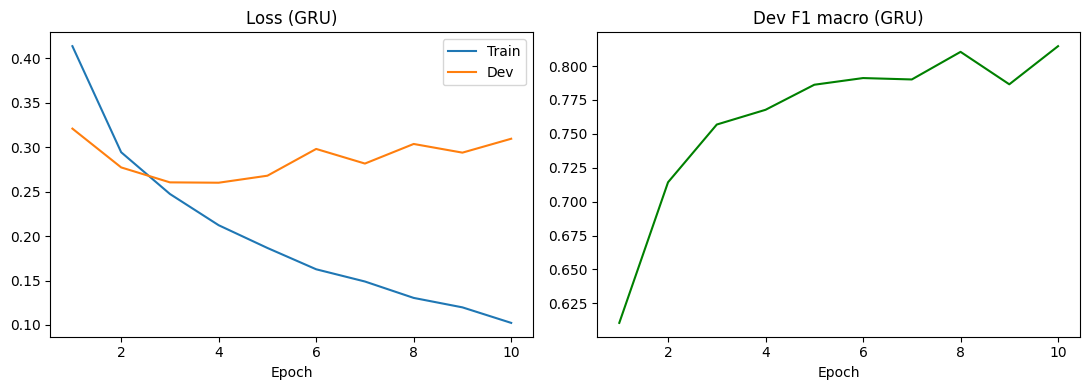

In [78]:
plot_history("gru")

#### Nhận xét: 
* Train loss: giảm đều qua từng epoch, giống với LSTM
* Dev loss: không quá khác biệt so với LSTM, thấp nhất ở epoch 3 đến 4 (khoảng 0.26). Overfit bắt đầu từ sau epoch 4
* Dev F1 macro: tăng khá đều đến khoảng 0.79 ở epoch 5 đến 7, rồi dao động (đỉnh 0.81 ở epoch 8, tụt ở epoch 9) và cao nhất ở epoch 10 (khoảng 0.815). F1 chưa ổn định, nên chọn theo epoch tốt nhất trên dev là cần thiết

#### 2.4. Load model dùng để dự đoán test

In [79]:
test_and_report("gru")

GRU - Test F1 macro: 0.7635
              precision    recall  f1-score   support

    negative     0.9010    0.9496    0.9247      1409
     neutral     0.5556    0.3593    0.4364       167
    positive     0.9345    0.9245    0.9295      1590

    accuracy                         0.9059      3166
   macro avg     0.7970    0.7445    0.7635      3166
weighted avg     0.8996    0.9059    0.9013      3166



#### Nhận xét
* Tổng thể: GRU accuracy 0.9059, tốt hơn so với LSTM một chút
* F1 macro: 0.7635, vẫn thấp hơn acccuracy nhiều, và cũng gặp tình trạng như LSTM là mất cân bằng lớp
* Phân loại 3 lớp: 2 lớp negative và positive tốt và ổn định, trong khi neutral vẫn gặp vấn đề tương tự
* Precision và recall của neutral: Precision 0.5556 cao hơn recall 0.3593, mô hình vẫn bỏ sót khoảng 64% câu neutral thật

#### 2.5. Confusion matrix

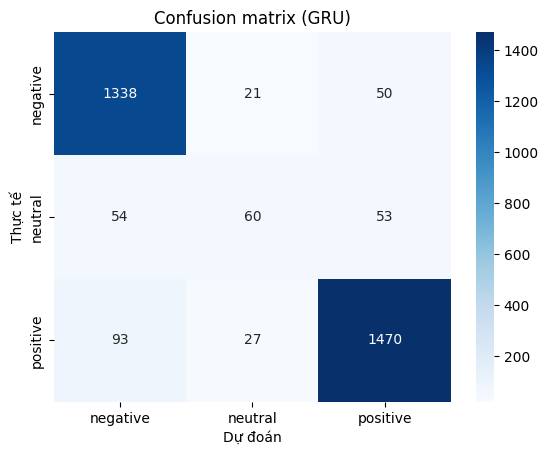

In [80]:
plot_cm("gru")

#### Nhận xét:
* Hai lớp lớn: negative đúng 1338/1409 và positive đúng 1470/1590, tốt và ngang LSTM
* Lớp neutral: đúng 56/167, cao hơn LSTM (53) và vẫn là điểm yếu chính
* Nhầm lẫn chính là 93 câu positive bị đoán thành negative còn 50 câu negative bị đoán thành positive. Lỗi neutral chia đều về 2 phía (54 và 53)

#### 2.6. Phân tích lỗi trên dev

In [81]:
error_analysis("gru")

GRU - 3 câu dự đoán sai trên dev:

Câu: thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .
Thật: neutral | Dự đoán: positive | Độ tự tin: 0.99

Câu: cô rất nghiêm .
Thật: negative | Dự đoán: positive | Độ tự tin: 0.94

Câu: ngoài ra cung cấp một vài thông tin bổ sung về việc học công nghệ thông tin hiệu quả hơn .
Thật: positive | Dự đoán: negative | Độ tự tin: 0.78



#### Nhận xét:
* Câu 1: GRU bị sai giống hệt LSTM, cũng đoán positive với độ tự tin gần như tuyệt đối. Có thể đây là lỗi do người gán nhãn chứ không phải do kiến trúc mô hình.
* Câu 2: Cũng giống LSTM, GRU đoán positive với độ tự tin 0.94. "Nghiêm" là từ mơ hồ nên cả hai mô hình đều không phân biệt được. Có thể xem đây là nhãn khó phân biệt
* Câu 3: Câu bị thiếu chủ ngữ và cũng bị cắt mất ngữ cảnh. Mô hình có thể đã bám vào cụm "một vài" nghe như hạn chế nên đoán negative với độ tự tin 0.78
* **Kết luận:** GRU sai đúng ba câu giống LSTM, nghĩa là hai mô hình cùng gặp một nhóm câu khó (nhãn mơ hồ và câu thiếu ngữ cảnh). Độ tự tin của GRU bằng hoặc thấp hơn LSTM (0.99, 0.94, 0.78 so với 0.99, 0.97, 0.87), nhưng ba câu này chỉ là ba câu sai đầu tiên trong dev nên chưa đủ để kết luận chung

#### 2.7. So sánh LSTM, GRU và baseline

In [82]:
names = {"tfidf": "TF-IDF + LogReg", "lstm": "LSTM 5 lớp", "gru": "GRU 5 lớp"}

table1 = []
for key in ["tfidf", "lstm", "gru"]:
    y = results[key]["test_labels"]
    p = results[key]["test_preds"]
    f1_each = f1_score(y, p, average=None)
    table1.append([names[key],
                   accuracy_score(y, p),
                   precision_score(y, p, average="macro"),
                   recall_score(y, p, average="macro"),
                   f1_score(y, p, average="macro"),
                   f1_each[0], f1_each[1], f1_each[2]])

df1 = pd.DataFrame(table1, columns=["Model", "Accuracy", "Precision-macro", "Recall-macro",
                                    "F1-macro", "F1-negative", "F1-neutral", "F1-positive"])
display(df1.set_index("Model").round(4))

table2 = []
for key in ["lstm", "gru"]:
    r = results[key]
    table2.append([names[key], r["test_f1_macro"], r["n_params"],
                   r["sec_per_epoch"], r["best_epoch"], r["best_dev_f1"]])

df2 = pd.DataFrame(table2, columns=["Model", "Test-F1-macro", "Số tham số", "Giây/epoch",
                                    "Epoch tốt nhất (dev)", "Dev F1 tốt nhất"])
display(df2.set_index("Model").round(4))

,Accuracy,Precision-macro,Recall-macro,F1-macro,F1-negative,F1-neutral,F1-positive
Model,,,,,,,
TF-IDF + LogReg,0.8932,0.7723,0.6843,0.7018,0.9134,0.2731,0.9190
LSTM 5 lớp,0.8999,0.7711,0.7332,0.7475,0.9205,0.3958,0.9261
GRU 5 lớp,0.9059,0.7970,0.7445,0.7635,0.9247,0.4364,0.9295


,Test-F1-macro,Số tham số,Giây/epoch,Epoch tốt nhất (dev),Dev F1 tốt nhất
Model,,,,,
LSTM 5 lớp,0.7475,3301207,4.4895,6,0.8069
GRU 5 lớp,0.7635,2632023,4.1932,10,0.8146


#### Nhận xét:
* Chất lượng: F1 macro của TF-IDF, LSTM, GRU lần lượt là 0.7018, 0.7475, 0.7635. Hai mô hình RNN đều cao hơn baseline
* LSTM và GRU: GRU chỉ chênh lệch nhỏ so với LSTM, chỉ chạy một seed và neutral chỉ có 167 câu test, nên chưa chắc GRU tốt hơn
* Lớp neutral: baseline chỉ đạt F1 0.2731, LSTM 0.3958, GRU 0.4364. Hai lớp còn lại ở cả ba mô hình đều trên 0.91, nên sự khác biệt chủ yếu nằm ở neutral
* Số tham số: GRU có 2632023 tham số, ít hơn LSTM (3301207)
* Thời gian: GRU mất 4.2349 giây/epoch, nhanh hơn LSTM (4.8910 giây/epoch)
* Epoch tốt nhất: LSTM là epoch 6 còn GRU là epoch cuối. Dev F1 có thể còn tăng nếu train thêm
* Dev và test: dev F1 của LSTM (0.7750) và GRU (0.8146) đều cao hơn test, chênh lệch nhẹ.

### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

#### 3.1. Kiểm tra đường dẫn + kích thước

In [83]:
BASE_DIR = "/kaggle/input/datasets/xuancuong1019/phoner-covid19"
print(os.listdir(BASE_DIR))

ner_train_df = pd.read_json(BASE_DIR + "/train_syllable.json", lines=True)
ner_dev_df = pd.read_json(BASE_DIR + "/dev_syllable.json", lines=True)
ner_test_df = pd.read_json(BASE_DIR + "/test_syllable.json", lines=True)

print("Train:", ner_train_df.shape)
print("Dev:", ner_dev_df.shape)
print("Test:", ner_test_df.shape)

['dev_syllable.json', 'test_syllable.json', 'train_syllable.json']
Train: (5027, 2)
Dev: (2000, 2)
Test: (3000, 2)


#### 3.2. Thống kê độ dài câu

In [84]:
ner_lengths = ner_train_df["words"].apply(len)
print(ner_lengths.describe())
print(ner_lengths.quantile([0.90, 0.95, 0.99]))

count    5027.000000
mean       33.328228
std        15.784414
min         7.000000
25%        22.000000
50%        30.000000
75%        41.000000
max       186.000000
Name: words, dtype: float64
0.90    54.0
0.95    64.0
0.99    84.0
Name: words, dtype: float64


#### 3.3. Xây dựng vocab cho word và tag

In [85]:
NER_MIN_FREQ = 2

ner_freq = Counter() 
for words in ner_train_df["words"]:
    ner_freq.update(words)

ner_vocab = {"<pad>": PAD, "<unk>": UNK}
for word, count in sorted(ner_freq.items()):
    if count >= NER_MIN_FREQ:
        ner_vocab[word] = len(ner_vocab)

total = sum(ner_freq.values())
covered = sum(c for c in ner_freq.values() if c>= NER_MIN_FREQ)
print("Kích thước vocab:", len(ner_vocab))
print("Tổng số token train:", total)
print("Coverage: %.2f%%" % (covered/total*100))

tag_list = sorted({tag for tags in ner_train_df["tags"] for tag in tags})
tag2id = {tag: i for i, tag in enumerate(tag_list)}
id2tag = {i: tag for tag, i in tag2id.items()}
NUM_TAGS = len(tag2id)

print("Số nhãn:", NUM_TAGS)
print(tag2id)
assert NUM_TAGS == 21

Kích thước vocab: 2813
Tổng số token train: 167541
Coverage: 99.31%
Số nhãn: 21
{'B-AGE': 0, 'B-DATE': 1, 'B-GENDER': 2, 'B-JOB': 3, 'B-LOCATION': 4, 'B-NAME': 5, 'B-ORGANIZATION': 6, 'B-PATIENT_ID': 7, 'B-SYMPTOM_AND_DISEASE': 8, 'B-TRANSPORTATION': 9, 'I-AGE': 10, 'I-DATE': 11, 'I-GENDER': 12, 'I-JOB': 13, 'I-LOCATION': 14, 'I-NAME': 15, 'I-ORGANIZATION': 16, 'I-PATIENT_ID': 17, 'I-SYMPTOM_AND_DISEASE': 18, 'I-TRANSPORTATION': 19, 'O': 20}


#### 3.4. Encoding

In [86]:
def encode_words(words):
    return [ner_vocab.get(w, UNK) for w in words]

def encode_tags(tags):
    return [tag2id[t] for t in tags]

for df in (ner_train_df, ner_dev_df, ner_test_df):
    df["input_ids"] = df["words"].apply(encode_words)
    df["tag_ids"] = df["tags"].apply(encode_tags)

print("Words   :", ner_train_df["words"].iloc[0][:8])
print("Input IDs:", ner_train_df["input_ids"].iloc[0][:8])
print("Tags    :", ner_train_df["tags"].iloc[0][:8])
print("Tag IDs :", ner_train_df["tag_ids"].iloc[0][:8])

Words   : ['Đồng', 'thời', ',', 'bệnh', 'viện', 'tiếp', 'tục', 'thực']
Input IDs: [2700, 2398, 9, 1557, 2579, 2414, 2556, 2405]
Tags    : ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']
Tag IDs : [20, 20, 20, 20, 20, 20, 20, 20]


#### 3.5. Padding cho NER

In [87]:
def ner_collate(batch):
    ids, tags = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids])  
    ids = pad_sequence(ids, batch_first=True, padding_value=PAD)      
    tags = pad_sequence(tags, batch_first=True, padding_value=-100)  
    return ids, tags, lengths

#### 3.6. Khởi tạo dataset

In [88]:
class NERDataset(Dataset):
    def __init__(self, df):
        self.input_ids = df["input_ids"].tolist()
        self.tag_ids = df["tag_ids"].tolist()

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, i):
        return torch.tensor(self.input_ids[i]), torch.tensor(self.tag_ids[i])
        
ner_train_dataset = NERDataset(ner_train_df)
ner_dev_dataset = NERDataset(ner_dev_df)
ner_test_dataset = NERDataset(ner_test_df)

#### 3.7. Khởi tạo DataLoader

In [89]:
NER_BATCH_SIZE = 32

ner_train_loader = DataLoader(ner_train_dataset, batch_size=NER_BATCH_SIZE, shuffle=True, collate_fn=ner_collate)
ner_dev_loader = DataLoader(ner_dev_dataset, batch_size=NER_BATCH_SIZE, shuffle=False, collate_fn=ner_collate)
ner_test_loader = DataLoader(ner_test_dataset, batch_size=NER_BATCH_SIZE, shuffle=False, collate_fn=ner_collate)

input_ids, tag_ids, lengths = next(iter(ner_train_loader))

print("Input shape:", input_ids.shape)
print("Tags shape:", tag_ids.shape)
print("Lengths shape:", lengths.shape)
print("Số batch (train/dev/test):", len(ner_train_loader), len(ner_dev_loader), len(ner_test_loader))

Input shape: torch.Size([32, 80])
Tags shape: torch.Size([32, 80])
Lengths shape: torch.Size([32])
Số batch (train/dev/test): 158 63 94


#### 3.8. BiLSTMEncoder: Embedding -> LSTM (bidirectional=True, 5 layer, hidden_size = 256) -> Linear (21 tag)

In [90]:
class BiLSTMEncoder(nn.Module):
    def __init__(self, vocab_size, emb_dim=300, hidden_size=256,
                 layers=5, dropout=0.3, num_tags=21):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden_size, num_layers=layers, batch_first=True, dropout=dropout, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size * 2, num_tags)   

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))                   
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=x.size(1))
        return self.fc(self.dropout(out))                        

#### 3.9. Khởi tạo model

In [91]:
set_seed(42)
ner_model = BiLSTMEncoder(len(ner_vocab), num_tags=NUM_TAGS).to(device)
print(ner_model)
print("Số tham số:", count_params(ner_model))

x, y, lens = next(iter(ner_train_loader))
with torch.no_grad():
    logits = ner_model(x.to(device), lens)
print("Logits:", logits.shape, "| Tags:", y.shape)
del ner_model

BiLSTMEncoder(
  (embedding): Embedding(2813, 300, padding_idx=0)
  (lstm): LSTM(300, 256, num_layers=5, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=21, bias=True)
)
Số tham số: 8305297
Logits: torch.Size([32, 69, 21]) | Tags: torch.Size([32, 69])


#### 3.10. Loss và optimizer

In [93]:
ner_criterion = nn.CrossEntropyLoss(ignore_index=-100)
NER_LR = 1e-3

#### 3.11. Hàm decode

In [94]:
def decode(logits, tag_ids, lengths):
    preds_ids = logits.argmax(dim=-1).cpu().tolist()
    golds_ids = tag_ids.cpu().tolist()
    pred_seqs, gold_seqs = [], []
    for i in range(len(lengths)):
        n = lengths[i].item()
        pred_seqs.append([id2tag[t] for t in preds_ids[i][:n]])
        gold_seqs.append([id2tag[t] for t in golds_ids[i][:n]])
    return pred_seqs, gold_seqs

#### 3.12. Huấn luyện 1 epoch và hàm evaluate

In [95]:
def ner_train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for x, y, lens in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x, lens)                                    
        loss = ner_criterion(logits.view(-1, NUM_TAGS), y.view(-1))    
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def ner_evaluate(model, loader):
    model.eval()
    total_loss = 0
    all_preds, all_golds = [], []
    with torch.no_grad():
        for x, y, lens in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x, lens)
            total_loss += ner_criterion(logits.view(-1, NUM_TAGS), y.view(-1)).item()
            preds, golds = decode(logits, y, lens)
            all_preds += preds
            all_golds += golds
    f1 = ent_f1(all_golds, all_preds, mode="strict", scheme=IOB2)
    return total_loss / len(loader), f1, all_preds, all_golds

#### 3.13. Training loop

In [96]:
ner_results = {}

def train_ner(epochs=10):
    set_seed(42)
    model = BiLSTMEncoder(len(ner_vocab), num_tags=NUM_TAGS).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=NER_LR)

    history = {"train_loss": [], "dev_loss": [], "dev_f1": []}
    best_f1 = 0
    best_epoch = 0
    best_state = None
    epoch_times = []

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss = ner_train_one_epoch(model, ner_train_loader, optimizer)
        dev_loss, dev_f1, _, _ = ner_evaluate(model, ner_dev_loader)
        epoch_times.append(time.time() - start)

        history["train_loss"].append(train_loss)
        history["dev_loss"].append(dev_loss)
        history["dev_f1"].append(dev_f1)

        if dev_f1 > best_f1:
            best_f1 = dev_f1
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
        print("Epoch %2d | train loss %.4f | dev loss %.4f | dev entity-F1 %.4f" % (epoch, train_loss, dev_loss, dev_f1))

    ner_results["history"] = history
    ner_results["best_dev_f1"] = best_f1
    ner_results["best_epoch"] = best_epoch
    ner_results["sec_per_epoch"] = sum(epoch_times) / len(epoch_times)
    ner_results["n_params"] = count_params(model)
    ner_results["best_state"] = best_state
    print("Best dev entity-F1: %.4f (epoch %d)" % (best_f1, best_epoch))

train_ner()

Epoch  1 | train loss 0.7781 | dev loss 0.3719 | dev entity-F1 0.6029
Epoch  2 | train loss 0.2097 | dev loss 0.2038 | dev entity-F1 0.7764
Epoch  3 | train loss 0.1159 | dev loss 0.1445 | dev entity-F1 0.8581
Epoch  4 | train loss 0.0825 | dev loss 0.1340 | dev entity-F1 0.8780
Epoch  5 | train loss 0.0621 | dev loss 0.1325 | dev entity-F1 0.8924
Epoch  6 | train loss 0.0532 | dev loss 0.1331 | dev entity-F1 0.9023
Epoch  7 | train loss 0.0459 | dev loss 0.1471 | dev entity-F1 0.8971
Epoch  8 | train loss 0.0436 | dev loss 0.1405 | dev entity-F1 0.9054
Epoch  9 | train loss 0.0348 | dev loss 0.1423 | dev entity-F1 0.9053
Epoch 10 | train loss 0.0301 | dev loss 0.1313 | dev entity-F1 0.9120
Best dev entity-F1: 0.9120 (epoch 10)


#### 3.14. Đường cong loss

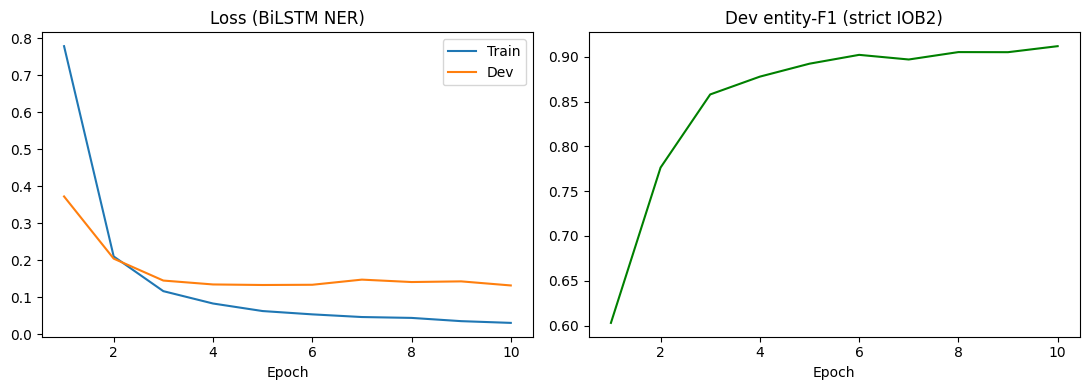

In [97]:
h = ner_results["history"]
epochs = range(1, len(h["train_loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, h["train_loss"], label="Train")
ax[0].plot(epochs, h["dev_loss"], label="Dev")
ax[0].set_title("Loss (BiLSTM NER)")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(epochs, h["dev_f1"], color="green")
ax[1].set_title("Dev entity-F1 (strict IOB2)")
ax[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()

#### Nhận xét:
* Train loss: giảm rất nhanh từ khoảng 0.78 xuống 0.2 sau 2 epoch, và còn khoảng 0.03 ở epoch 10
* Dev loss: giảm đến khoảng 0.13 ở epoch 4, sau đó gần như đi ngang (0.13 đến 0.15). Khoảng cách với train loss rộng dần, có overfit nhẹ nhưng dev loss không tăng mạnh
* Dev entity-F1: tăng nhanh đến epoch 3 (khoảng 0.86), rồi tăng chậm và đạt cao nhất ở epoch 10 (khoảng 0.912). Chỉ dip nhẹ ở epoch 7, nên đường cong khá ổn định và gần hội tụ

#### 3.15. Load model tốt nhất để dự đoán test

In [98]:
ner_model = BiLSTMEncoder(len(ner_vocab), num_tags=NUM_TAGS).to(device)
ner_model.load_state_dict(ner_results["best_state"])

_, _, test_preds, test_golds = ner_evaluate(ner_model, ner_test_loader)

ner_results["test_precision"] = ent_precision(test_golds, test_preds, mode="strict", scheme=IOB2)
ner_results["test_recall"] = ent_recall(test_golds, test_preds, mode="strict", scheme=IOB2)
ner_results["test_f1"] = ent_f1(test_golds, test_preds, mode="strict", scheme=IOB2)

print("Test (entity-level, strict IOB2)")
print("Precision: %.4f" % ner_results["test_precision"])
print("Recall   : %.4f" % ner_results["test_recall"])
print("Micro-F1 : %.4f" % ner_results["test_f1"])

Test (entity-level, strict IOB2)
Precision: 0.9113
Recall   : 0.8917
Micro-F1 : 0.9014


### Nhận xét:
* Micro-F1: đạt 0.9014, mô hình nhìn chung nhận diện tốt các thực thể
* Precision và recall: precision 0.9113 cao hơn recall 0.8917, mô hình ít dự đoán thừa nhưng bỏ sót nhiều

#### 3.16. F1 từng loại thực thể

In [99]:
report = ent_report(test_golds, test_preds, mode="strict", scheme=IOB2, output_dict=True, zero_division=0)

rows = []
for entity, scores in report.items():
    if entity in ["micro avg", "macro avg", "weighted avg"]:
        continue
    rows.append({"Entity": entity, "Precision": scores["precision"], "Recall": scores["recall"],
                 "F1": scores["f1-score"], "Support": scores["support"]})

type_df = pd.DataFrame(rows).sort_values("F1").set_index("Entity")
display(type_df.round(4))

,Precision,Recall,F1,Support
Entity,,,,
JOB,0.6667,0.4855,0.5619,173
NAME,0.7544,0.5409,0.6300,318
ORGANIZATION,0.8373,0.7808,0.8081,771
SYMPTOM_AND_DISEASE,0.8612,0.7755,0.8161,1136
TRANSPORTATION,0.9382,0.8653,0.9003,193
LOCATION,0.9117,0.9063,0.9090,4441
GENDER,0.9416,0.9416,0.9416,462
AGE,0.9481,0.9416,0.9448,582
PATIENT_ID,0.9346,0.9696,0.9518,2005


#### Nhận xét:
* Các thực thể tốt có F1 ≥ 0.9. Đây là các thực thể rõ ràng như ngày tháng, mã số hay tuổi
* Nhóm trung bình: gồm có SYMPTOM_AND_DISEASE (0.8161) và ORGANIZATION (0.8081). Hai loại này cụm từ dài và đa dạng nên khó cắt đúng ranh giới
* Nhóm yếu: JOB (0.5619) và NAME (0.6300) kém nhất. Recall của cả 2 đều thấp hơn precision rõ, nghĩa là mô hình chủ yếu là bỏ sót
* Số lượng mẫu: JOB chỉ có 173 và NAME có 318 thực thể test, ít hơn so với LOCATION (4441). Vì thế micro-f1 cao nhưng hai thực thể trên vẫn yếu

#### 3.17 Bảng đánh giá tổng hợp

In [100]:
summary = pd.DataFrame([{
    "Số tham số": ner_results["n_params"],
    "Giây/epoch": ner_results["sec_per_epoch"],
    "Epoch tốt nhất (dev)": ner_results["best_epoch"],
    "Dev entity-F1": ner_results["best_dev_f1"],
    "Test Precision": ner_results["test_precision"],
    "Test Recall": ner_results["test_recall"],
    "Test micro-F1": ner_results["test_f1"],
}], index=["BiLSTM-5"])
display(summary.round(4))

,Số tham số,Giây/epoch,Epoch tốt nhất (dev),Dev entity-F1,Test Precision,Test Recall,Test micro-F1
BiLSTM-5,8305297,7.6756,10,0.912,0.9113,0.8917,0.9014


#### Nhận xét:
* Số tham số: 8,305,297, nhiều hơn hẳn LSTM và GRU ở Bài 1, 2 vì dùng 2 chiều và 5 lớp.
* Thời gian: 7.603 giây/epoch, chậm hơn LSTM (4.8910) và GRU (4.2349), do xử lý 2 chiều và câu NER dài hơn.
* Epoch tốt nhất: Đạt kết quả tốt nhất tại epoch 10
* Dev và test: dev entity F1 0.912 gần với test micro F1 0.9014, mô hình tổng quát hóa ổn.

#### 3.18. Phân tích lỗi trên dev

In [101]:
_, _, dev_preds, dev_golds = ner_evaluate(ner_model, ner_dev_loader)

counts = {"correct": 0, "boundary": 0, "wrong_type": 0,
          "missed": 0, "spurious": 0, "invalid_iob2": 0}

for gold_tags, pred_tags in zip(dev_golds, dev_preds):
    gold_ents = get_entities(gold_tags)
    pred_ents = get_entities(pred_tags)

    for g in gold_ents:
        if g in pred_ents:
            counts["correct"] += 1
            continue
        overlap = []
        for p in pred_ents:
            if p[1] <= g[2] and p[2] >= g[1]:
                overlap.append(p)

        if len(overlap) == 0:
            counts["missed"] += 1
        else:
            same_span = False
            same_type = False
            for p in overlap:
                if p[1] == g[1] and p[2] == g[2]:
                    same_span = True
                if p[0] == g[0]:
                    same_type = True
            if same_span or not same_type:
                counts["wrong_type"] += 1
            else:
                counts["boundary"] += 1
                
    for p in pred_ents:
        has_gold = False
        for g in gold_ents:
            if g[1] <= p[2] and p[1] <= g[2]:
                has_gold = True
        if not has_gold:
            counts["spurious"] += 1

    prev = "O"
    for tag in pred_tags:
        if tag.startswith("I-") and prev[2:] != tag[2:]:
            counts["invalid_iob2"] += 1
        prev = tag

error_names = {"correct": "Đúng hoàn toàn", "boundary": "Sai ranh giới", "wrong_type": "Nhầm loại",
               "missed": "Bỏ sót", "spurious": "Dự đoán thừa", "invalid_iob2": "Chuỗi IOB2 không hợp lệ"}

rows = []
for key in error_names:
    rows.append([error_names[key], counts[key]])
display(pd.DataFrame(rows, columns=["Kiểu", "Số lượng"]))

,Kiểu,Số lượng
0,Đúng hoàn toàn,6774
1,Sai ranh giới,273
2,Nhầm loại,156
3,Bỏ sót,275
4,Dự đoán thừa,210
5,Chuỗi IOB2 không hợp lệ,100


#### Nhận xét:
* Bỏ sót (275) và sai ranh giới (273) là hai kiểu lỗi nhiều nhất, mỗi kiểu khoảng 3.7% số thực thể thật trên dev.
  * Sai ranh giới: mô hình nhận ra thực thể nhưng cắt thiếu hoặc thừa âm tiết, ví dụ tự tạo: đúng là [Bệnh viện Hoa Mai] nhưng dự đoán [Bệnh viện]. Vì chấm strict nên lệch một âm tiết là sai cả thực thể.
  * Bỏ sót: cả cụm bị gán toàn O, ví dụ tự tạo: "ho khan kéo dài" không được nhận là triệu chứng.
* Dự đoán thừa (210): mô hình gán thực thể cho cụm không phải thực thể, ví dụ tự tạo: "Khu vực" ở đầu câu bị gán LOCATION. Kiểu này làm giảm precision.
* Nhầm loại (156) ít nhất: đúng ranh giới nhưng sai loại, ví dụ tự tạo: "Hoa Mai" là tên tổ chức nhưng bị gán NAME. Mô hình định vị thực thể tốt hơn là phân biệt loại.
* Chuỗi IOB2 không hợp lệ (100): mô hình dự đoán I-X mà không đứng sau B-X hoặc I-X. Mô hình gán nhãn từng token độc lập nên không có ràng buộc giữa các nhãn liền kề. Có thể xử lý bằng CRF hoặc hậu xử lý sửa chuỗi.
* Lưu ý: bảng lỗi dùng cách tách thực thể lỏng nên có thể lệch nhẹ so với F1 strict.

#### 3.19. Bảng tổng hợp so sánh tất cả mô hình (Câu 3 khác với câu 1, 2 nên không so sánh trực tiếp)

In [103]:
rows = []

r = results["tfidf"]
rows.append(["TF-IDF + Logistic Regression (Macro-F1)",
             "%.4f" % r["best_dev_f1"],
             "%.4f" % r["test_f1_macro"],
             r["config"] + " | " + "{:,}".format(r["n_params"]) + " tham số",
             "%.1f (thời gian fit)" % r["fit_time"]])

for key, name in [("lstm", "LSTM 5 lớp (Macro-F1)"), ("gru", "GRU 5 lớp (Macro-F1)")]:
    r = results[key]
    rows.append([name,
                 "%.4f" % r["best_dev_f1"],
                 "%.4f" % r["test_f1_macro"],
                 "{:,}".format(r["n_params"]),
                 "%.2f" % r["sec_per_epoch"]])

rows.append(["BiLSTM NER 5 lớp (Entity-F1)",
             "%.4f" % ner_results["best_dev_f1"],
             "%.4f" % ner_results["test_f1"],
             "{:,}".format(ner_results["n_params"]),
             "%.2f" % ner_results["sec_per_epoch"]])

final_df = pd.DataFrame(rows, columns=["Mô hình", "Dev F1 tốt nhất", "Test F1", "Tham số", "Giây/epoch"])
display(final_df.set_index("Mô hình"))

,Dev F1 tốt nhất,Test F1,Tham số,Giây/epoch
Mô hình,,,,
TF-IDF + Logistic Regression (Macro-F1),0.7385,0.7018,"ngram(1,2), min_df=2, C=10 | 38,568 tham số",5.0 (thời gian fit)
LSTM 5 lớp (Macro-F1),0.8069,0.7475,"3,301,207",4.49
GRU 5 lớp (Macro-F1),0.8146,0.7635,"2,632,023",4.19
BiLSTM NER 5 lớp (Entity-F1),0.9120,0.9014,"8,305,297",7.68
